# CRISP-DM phase 2 : Data Understanding, D11 (Diabetic Retinopathy Debrecen, UCI / Antal & Hajdu 2014)

Responsable : Omar (diabète)

**À surveiller :** 1151 images rétiniennes du jeu Messidor. 19 descripteurs continus extraits par traitement d'images (microanévrismes, exsudats, disque optique). Fichier initial au format ARFF converti en CSV.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import load, REGISTRY

DS = 'D11'
df, target = load(DS)   # vérifie aussi la taille face au tableau 2 de l'article
REGISTRY[DS]['name'], df.shape

[D11] lignes=1151 pos=611 neg=540 | article: lignes=1151 pos=611 neg=540 -> OK


('Diabetic Retinopathy Debrecen', (1151, 20))

## 1. Structure et dictionnaire des variables
Compléter le tableau dans le rapport : nom, signification médicale, type, unité.

In [2]:
df.head()

,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,feat_10,feat_11,feat_12,feat_13,feat_14,feat_15,feat_16,feat_17,feat_18,Class
0,1,1,22,22,22,19,18,14,49.895756,17.775994,5.270920,0.771761,0.018632,0.006864,0.003923,0.003923,0.486903,0.100025,1,0
1,1,1,24,24,22,18,16,13,57.709936,23.799994,3.325423,0.234185,0.003903,0.003903,0.003903,0.003903,0.520908,0.144414,0,0
2,1,1,62,60,59,54,47,33,55.831441,27.993933,12.687485,4.852282,1.393889,0.373252,0.041817,0.007744,0.530904,0.128548,0,1
3,1,1,55,53,53,50,43,31,40.467228,18.445954,9.118901,3.079428,0.840261,0.272434,0.007653,0.001531,0.483284,0.114790,0,0
4,1,1,44,44,44,41,39,27,18.026254,8.570709,0.410381,0.000000,0.000000,0.000000,0.000000,0.000000,0.475935,0.123572,0,1


In [3]:
pd.DataFrame({'dtype': df.dtypes, 'n_unique': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

,dtype,n_unique,min,max
feat_0,int64,2,0.000000,1.000000
feat_1,int64,2,0.000000,1.000000
feat_2,int64,110,1.000000,151.000000
feat_3,int64,104,1.000000,132.000000
feat_4,int64,99,1.000000,120.000000
feat_5,int64,91,1.000000,105.000000
feat_6,int64,84,1.000000,97.000000
feat_7,int64,69,1.000000,89.000000
feat_8,float64,1141,0.349274,403.939108
feat_9,float64,1141,0.000000,167.131427


## 2. Variable cible

Class
0    540
1    611
Name: count, dtype: int64 
 Class
0    0.469
1    0.531
Name: count, dtype: float64


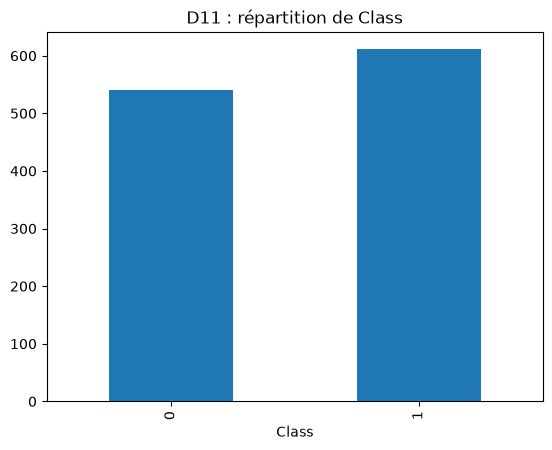

In [4]:
counts = df[target].value_counts().sort_index()
print(counts, '\n', (counts / len(df)).round(3))
counts.plot.bar(title=f'{DS} : répartition de {target}')
plt.show()

## 3. Valeurs manquantes (vraies et codées)

In [5]:
print('Valeurs nulles explicites :')
print(df.isna().sum()[df.isna().sum() > 0])

# Zéros médicalement impossibles (spécifique au diabète)
for c in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    if c in df:
        z = (df[c] == 0).sum()
        print(f'{c} = 0 : {z} ({z / len(df) * 100:.1f}%)')

Valeurs nulles explicites :
Series([], dtype: int64)


## 4. Doublons
L'article ne dit pas les avoir supprimés : on les **garde** pour reproduire ses résultats, puis on relance avec `--dedup` pour mesurer leur effet.

In [6]:
n_dup = df.duplicated().sum()
print(f'{n_dup} doublons sur {len(df)} lignes ({n_dup / len(df) * 100:.1f}%) -> {len(df) - n_dup} lignes uniques')
print('Répartition de la cible après déduplication :')
print(df.drop_duplicates()[target].value_counts())

5 doublons sur 1151 lignes (0.4%) -> 1146 lignes uniques
Répartition de la cible après déduplication :
Class
1    606
0    540
Name: count, dtype: int64


## 5. Statistiques descriptives et distributions

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
feat_0,1151.0,1.00,0.06,0.00,1.00,1.00,1.00,1.00
feat_1,1151.0,0.92,0.27,0.00,1.00,1.00,1.00,1.00
feat_2,1151.0,38.43,25.62,1.00,16.00,35.00,55.00,151.00
feat_3,1151.0,36.91,24.11,1.00,16.00,35.00,53.00,132.00
feat_4,1151.0,35.14,22.81,1.00,15.00,32.00,51.00,120.00
feat_5,1151.0,32.30,21.11,1.00,14.00,29.00,48.00,105.00
feat_6,1151.0,28.75,19.51,1.00,11.00,25.00,43.00,97.00
feat_7,1151.0,21.15,15.10,1.00,8.00,18.00,32.00,89.00
feat_8,1151.0,64.10,58.49,0.35,22.27,44.25,87.80,403.94
feat_9,1151.0,23.09,21.60,0.00,7.94,17.04,31.31,167.13


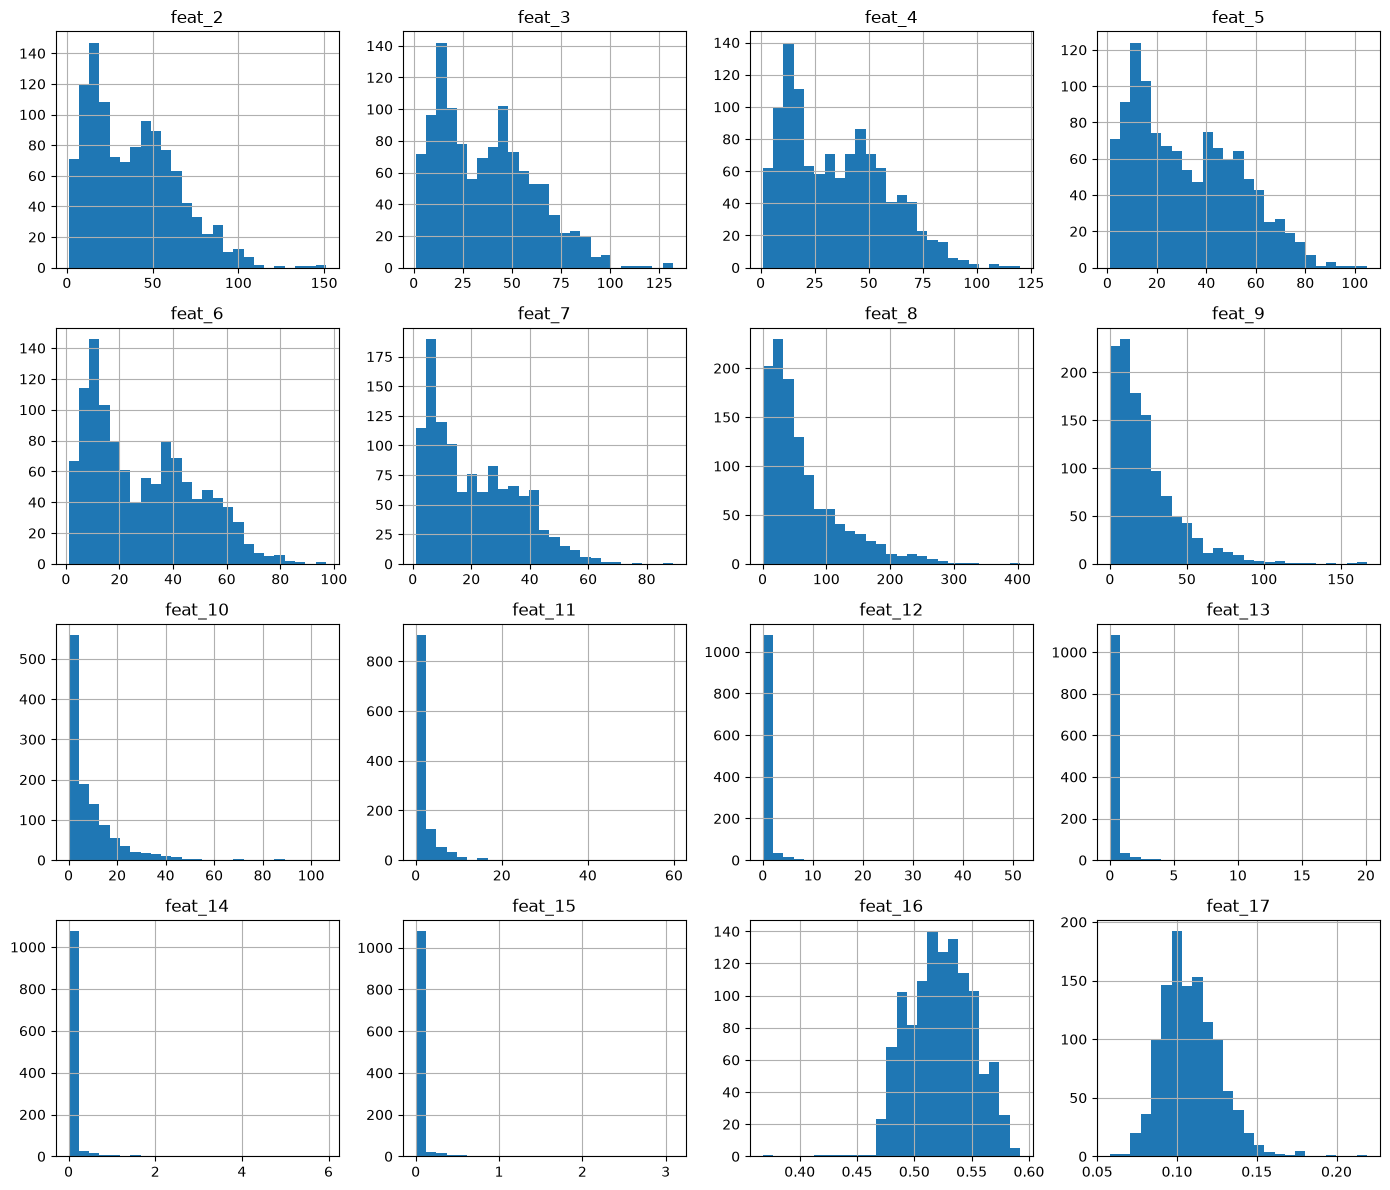

In [8]:
num = [c for c in df.columns if c != target and pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 5]
if num:
    df[num].hist(bins=25, figsize=(14, 3 * ((len(num) + 3) // 4)), layout=(-1, 4))
    plt.tight_layout()
    plt.show()
else:
    print('Pas de variables numériques continues (> 5 modalités)')

## 6. Valeurs aberrantes (méthode IQR)
Interpréter médicalement : erreur de saisie ou patient réellement extrême ?

In [9]:
if num:
    q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
    print(outliers[outliers > 0])
else:
    print('Aucune variable numérique continue')

feat_14    226
feat_13    204
feat_12    183
feat_15    180
feat_11    127
feat_10     76
feat_8      60
feat_9      57
feat_17     14
feat_2       7
feat_3       6
feat_4       4
feat_16      4
feat_7       3
feat_6       1
feat_5       1
dtype: int64


## 7. Variables selon la classe

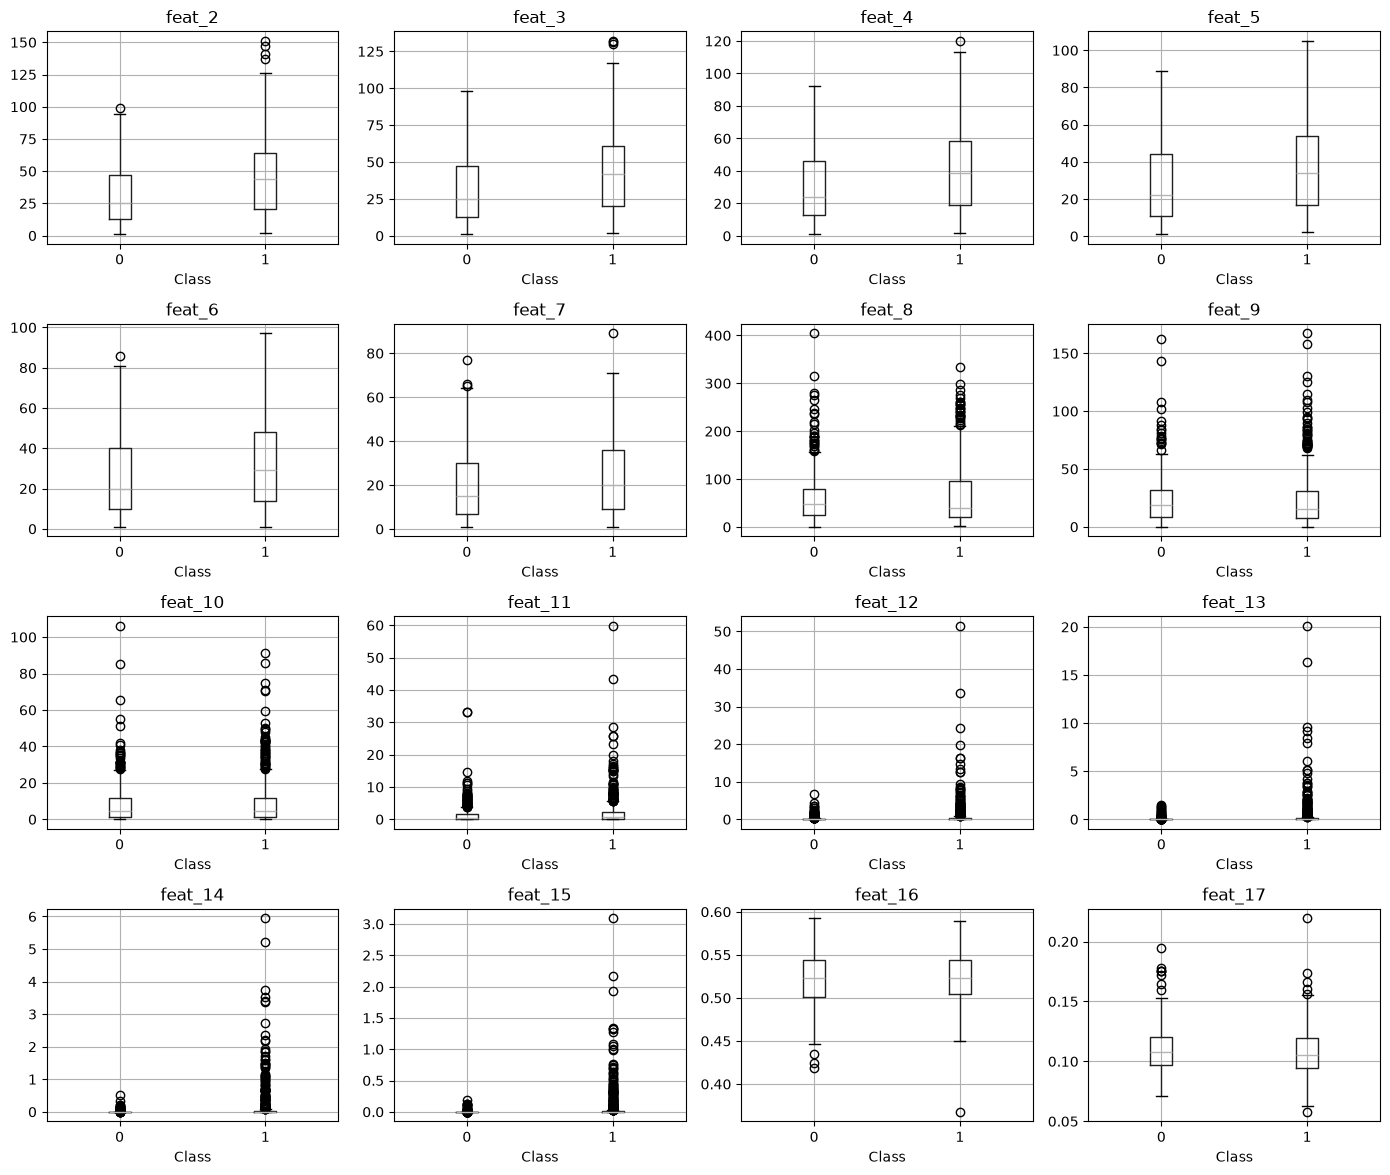

In [10]:
if num:
    fig, axes = plt.subplots((len(num) + 3) // 4, 4, figsize=(14, 3 * ((len(num) + 3) // 4)))
    for ax, c in zip(axes.flat, num):
        df.boxplot(column=c, by=target, ax=ax)
    plt.suptitle('')
    plt.tight_layout()
    plt.show()

In [11]:
cat = [c for c in df.columns if c != target and (df[c].nunique() <= 5 or not pd.api.types.is_numeric_dtype(df[c]))]
for c in cat[:10]:
    print(f'=== {c} vs {target} ===')
    print(pd.crosstab(df[c], df[target], normalize='index').round(2), '\n')

=== feat_0 vs Class ===
Class      0     1
feat_0            
0       1.00  0.00
1       0.47  0.53 

=== feat_1 vs Class ===
Class      0     1
feat_1            
0       0.34  0.66
1       0.48  0.52 

=== feat_18 vs Class ===
Class       0     1
feat_18            
0        0.45  0.55
1        0.50  0.50 



## 8. Corrélations

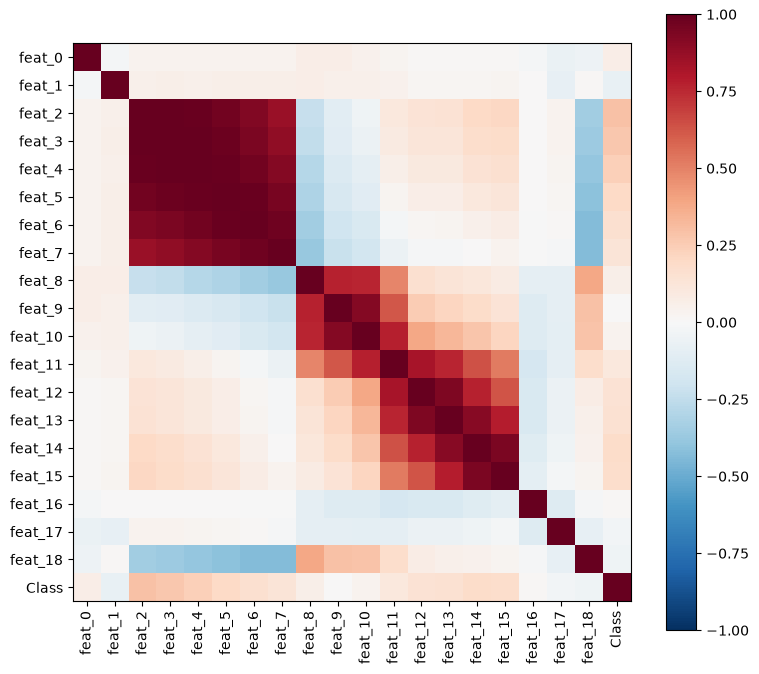

Corrélations avec la cible :
feat_2     0.293
feat_3     0.266
feat_4     0.235
feat_5     0.198
feat_14    0.185
feat_15    0.177
feat_6     0.162
feat_13    0.151
feat_12    0.142
feat_7     0.128
feat_11    0.104
feat_1    -0.077
feat_0     0.063
feat_8     0.058
feat_18   -0.042
feat_10    0.038
feat_17   -0.031
feat_16    0.008
feat_9     0.000
Name: Class, dtype: float64


In [12]:
corr = df.select_dtypes('number').corr()
if len(corr) > 1:
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.columns)
    plt.colorbar(im)
    plt.show()
    if target in corr.columns:
        print('Corrélations avec la cible :')
        print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3))

## 9. Conclusions pour la préparation (phase 3)

- Variables à encoder : aucune, les 19 caractéristiques sont numériques. Cible binaire {0, 1}.
- Valeurs manquantes / codées à traiter : aucune valeur manquante (qualité des descripteurs Messidor).
- Doublons : 5 doublons détectés.
- Normalisation : Indispensable (échelles très disparates entre le nombre de microanévrismes et les diamètres optiques).